# Vector-field benchmark: COMET vs scKINETICS vs CellRank

Metric computation lives in **`new_metrics.py`** (imported as `nm` only when recomputing). The precomputed results are in **`data/`**, and by default the notebook reads them from there. Calling the metric functions, caching and all plotting are in this notebook.

**Methods.**
* **COMET** uses its full field: committor direction + chromatin lead + regulatory-consistency GRN tilt (λ = 0.5, from the saved GRN). The chromatin lead's ATAC–RNA gate is off on AML and hair follicle, as in COMET itself.
* **scKINETICS** uses its gene-space velocity.
* **CellRank** uses scVelo stochastic velocity. It is available only where spliced/unspliced reads exist (AML, myeloid progenitors, hair follicle).

COMET gets no root and no labels.

**Pseudotimes.**
* **COMET pseudotime** converts the full field to a pseudotime the scVelo way. Steps:
  1. scVelo velocity graph (Decipher-latent kNN).
  2. scVelo transition matrix $T$.
  3. Its scalar potential: the least-squares fit of $\varphi_j - \varphi_i \approx (T_{ij} - T_{ji})/(T_{ij} + T_{ji})$ over mutual neighbours.

  This is the same conversion as "scKINETICS (graph flow)".
* **scKINETICS and CellRank** use the best of each family's pseudotime variants.

**Metrics.** Each method's velocity becomes one transition matrix on one shared graph:
$P_{ij} \propto \exp(10\cos(v_i, x_j - x_i))$ over 30 nearest neighbours, and $T = 0.8P + 0.2\,\text{uniform}$.

| metric | definition |
|---|---|
| **Pair AUC** (pseudotime) | $\frac{1}{|\mathcal P|}\sum_{(a,d)\in\mathcal P} P(\text{pt}_{d} > \text{pt}_{a})$ over every ancestor → descendant cluster pair of the known tree. Chance is 0.5. |
| **Forward transport** (field) | $f_i = m_i^{k}(\text{Desc}) - m_i^{k}(\text{Anc})$ after $k = 30$ steps. Only the directional part $\tfrac12[f(v) - f(-v)]$ is kept. Averaged per cell, then over clusters. Graph spaces: **Decipher latent**, and **gene PCA** (independent of COMET). |

**Uncertainty.**
* 95% bootstrap CIs over cells. Transport is resampled within clusters.
* Chance for transport is the range of 20 random Gaussian gene-space fields (2.5–97.5%).

In [1]:
import os, sys, pickle, importlib
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.stats import rankdata

USE_PRECOMPUTED = True           # True: read the precomputed metrics in data/*.csv (no raw data or other code needed)
                                 # False: recompute every metric with new_metrics.py (needs the raw data paths listed
                                 #        there) and overwrite data/*.csv
RECOMPUTE = False                # only when USE_PRECOMPUTED is False: ignore the per-dataset cache in cache/
COMET_PT_HOW = "potential"       # only when recomputing: "potential" (default) or "scvelo_vpt" (scVelo's own velocity_pseudotime)

HERE = os.path.abspath(".")                       # this folder
DATA, FIGS, CACHE = f"{HERE}/data", f"{HERE}/figs", f"{HERE}/cache"
os.makedirs(FIGS, exist_ok=True)
if not USE_PRECOMPUTED:
    sys.path.insert(0, HERE); import new_metrics as nm; importlib.reload(nm)


## Style

In [2]:
DATASETS = {"hema": "Human hematopoiesis", "nestorowa": "Mouse HSPCs", "paul15": "Mouse myeloid progenitors",
            "aml89": "AML (08H089)", "ma2020": "Hair follicle"}

METHODS = ["COMET", "scKINETICS", "CellRank"]
SPACES = ["Decipher latent", "gene PCA"]      # graph spaces of the transport metric (as in new_metrics.SPACES)
K_STEPS = 30                                   # transport steps (new_metrics.K_STEPS)
TREES = {  # parent -> children: the cell-type tree every metric scores against (new_metrics.TREES)
    "hema": {"HSC": ["MPP"], "MPP": ["CMP", "MLP"], "CMP": ["MEP", "GMP"], "MLP": ["GMP"]},
    "aml89": {"immature": ["blast0"], "blast0": ["blast1"], "blast1": ["blast2"], "blast2": ["blast3"]},
    "paul15": {"MEP": ["Erythroids", "Megakaryocytes"], "GMP": ["late_GMP"], "late_GMP": ["Granulocytes", "Monocytes"]},
    "ma2020": {"TAC-1": ["TAC-2"], "TAC-2": ["IRS", "Hair Shaft-Cuticle/Cortex", "Medulla"]},
    "nestorowa": {"LT-HSC": ["MPP"], "MPP": ["CMP", "LMPP"], "CMP": ["MEP", "GMP"]},
}
COLORS = {"COMET": "#C9027A", "scKINETICS": "#3E7CB1", "CellRank": "#E39B2D", "null": "#E6E6E6"}
TREE_ORDER = {
    "hema": ["HSC", "MPP", "CMP", "MLP", "MEP", "GMP"],
    "nestorowa": ["LT-HSC", "MPP", "CMP", "LMPP", "MEP", "GMP"],
    "paul15": ["MEP", "Erythroids", "Megakaryocytes", "GMP", "late_GMP", "Granulocytes", "Monocytes"],
    "aml89": ["immature", "blast0", "blast1", "blast2", "blast3"],
    "ma2020": ["TAC-1", "TAC-2", "IRS", "Hair Shaft-Cuticle/Cortex", "Medulla"],
}
SHORT = {"Hair Shaft-Cuticle/Cortex": "Hair shaft", "Erythroids": "Ery", "Megakaryocytes": "Mk",
         "Granulocytes": "Gran", "Monocytes": "Mono", "late_GMP": "late GMP"}
CT_PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756", "#72B7B2", "#EECA3B", "#9D755D"]
OTHER = "#D9D9D9"                 # cells outside the scored cell-type tree: drawn grey, not in the legend
INK = (0.1, 0.1, 0.1)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#B2182B", "#F4A582", "#FFFFFF", "#92C5DE", "#2166AC"])
METRICS = [("pair AUC", "pseudotime", "Pseudotime\npair AUC"),
           ("transport", "Decipher latent", "Transport\nDecipher latent"),
           ("transport", "gene PCA", "Transport\ngene PCA")]

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Nimbus Sans", "Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5, "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5,
    "ytick.major.size": 2.5, "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "svg.fonttype": "none"})

def save(fig, name, formats=("pdf", "png", "svg")):
    for ext in formats: fig.savefig(f"{FIGS}/{name}.{ext}")

# per-dataset cell-type colours that override CT_PALETTE (paul15: the palette of the Paul bio figures)
CT_COLORS = {"paul15": {"MEP": "#2A78D6", "Erythroids": "#1BAF7A", "Megakaryocytes": "#EB6834", "GMP": "#EDA100",
                        "late_GMP": "#E87BA4", "Granulocytes": "#008300", "Monocytes": "#4A3AA7"}}

def celltype_palette(ds, labels):
    pal = CT_COLORS.get(ds) or {c: CT_PALETTE[i % len(CT_PALETTE)] for i, c in enumerate(TREE_ORDER[ds])}
    return {c: pal.get(c, OTHER) for c in np.unique(labels)}

def get(ds, m, metric, space):
    q = S.query("dataset==@ds and method==@m and metric==@metric and space==@space")
    return (q.value.iloc[0], q.lo.iloc[0], q.hi.iloc[0]) if len(q) else (np.nan, np.nan, np.nan)

def chance(ds, metric, space):
    return (0.5, 0.5, 0.5) if metric == "pair AUC" else get(ds, "random field (null)", metric, space)

def methods_in(ds): return [m for m in METHODS if m in R[ds]["arrows"]]

## Metrics
With `USE_PRECOMPUTED = True` (default), everything is read from `data/` and nothing is recomputed:
* `per_cell.csv`: coordinates, cell type, root, each method's pseudotime, 2D arrows and per-cell transport.
* `summary.csv`: metric values with 95% CIs.
* `pair_auc.csv`: AUC for each ancestor → descendant pair.
* `transport_curves.csv`: transport at every step, including the random fields.

With `USE_PRECOMPUTED = False`, `compute_dataset` recomputes every metric with `new_metrics.py` (needs the raw data), caches each dataset in `cache/` and rewrites `data/`.

In [3]:
def compute_dataset(ds):
    D = nm.load_dataset(ds, comet_pt_how=COMET_PT_HOW); lab, ti = D["lab"], D["ti"]
    rec, pairs = [], []
    out = dict(cells=D["cells"], emb=D["emb"], lab=lab, root_mask=D["root_mask"], pt=D["pt"], pt_variant=D["pt_variant"],
               arrows={}, tr={}, curve={}, null_curve={}, n_cells=len(lab))
    # pseudotime: pair AUC
    for m, pt in D["pt"].items():
        v, lo, hi, per = nm.pair_auc_score(pt, lab, ti)
        rec.append(dict(dataset=ds, method=m, metric="pair AUC", space="pseudotime", value=v, lo=lo, hi=hi,
                        variant=D["pt_variant"][m]))
        pairs += [dict(dataset=ds, method=m, pair=f"{a} → {d}", value=x) for (a, d), x in per.items()]
    # field: forward transport in each graph space + the 2D arrows for display
    for m, (Xz, V) in D["fields"].items():
        out["arrows"][m] = nm.arrows_2d(D, m)
        for s in SPACES:
            f = nm.transport(D["knn"][s], Xz, V, lab, ti)
            v, lo, hi = nm.transport_score(f, lab)
            out["tr"][s, m] = f[-1]; out["curve"][s, m] = nm.transport_curve(f, lab)
            rec.append(dict(dataset=ds, method=m, metric="transport", space=s, value=v, lo=lo, hi=hi))
    for s in SPACES:
        nc = nm.null_transport(D, s); out["null_curve"][s] = nc; x = nc[:, -1]
        rec.append(dict(dataset=ds, method="random field (null)", metric="transport", space=s, value=np.median(x),
                        lo=np.percentile(x, 2.5), hi=np.percentile(x, 97.5)))
    return out, pd.DataFrame(rec), pd.DataFrame(pairs)

SPACE_KEY = {"Decipher latent": "latent", "gene PCA": "genePCA"}
NULL = "random field (null)"

def export_csvs(R, S, PAIRS, out=DATA):
    """everything the figures need, as four CSVs: per_cell, summary (metric values + 95% CIs), pair_auc (per
    ancestor -> descendant pair) and transport_curves (cluster-balanced transport at every step, incl. the null fields)"""
    os.makedirs(out, exist_ok=True); cells, curves = [], []
    for ds, r in R.items():
        df = pd.DataFrame({"dataset": ds, "cell": r["cells"], "x": r["emb"][:, 0], "y": r["emb"][:, 1],
                           "cell_type": r["lab"], "root": r["root_mask"]})
        for m in METHODS:
            df[f"pt_{m}"] = r["pt"].get(m, np.nan)
            A = r["arrows"].get(m)
            df[f"arrow_x_{m}"] = np.nan if A is None else A[:, 0]; df[f"arrow_y_{m}"] = np.nan if A is None else A[:, 1]
            for sp in SPACES: df[f"transport_{SPACE_KEY[sp]}_{m}"] = r["tr"].get((sp, m), np.nan)
        cells.append(df)
        for (sp, m), y in r["curve"].items():
            curves += [dict(dataset=ds, space=sp, method=m, rep=-1, k=k + 1, value=v) for k, v in enumerate(y)]
        for sp, nc in r["null_curve"].items():
            curves += [dict(dataset=ds, space=sp, method=NULL, rep=q, k=k + 1, value=v)
                       for q, y in enumerate(nc) for k, v in enumerate(y)]
    pd.concat(cells).to_csv(f"{out}/per_cell.csv", index=False)
    S.to_csv(f"{out}/summary.csv", index=False); PAIRS.to_csv(f"{out}/pair_auc.csv", index=False)
    pd.DataFrame(curves).to_csv(f"{out}/transport_curves.csv", index=False)

def load_csvs(src=DATA):
    """inverse of export_csvs -> R (per-dataset dict), S (summary), PAIRS"""
    rd = lambda f: pd.read_csv(f"{src}/{f}.csv", float_precision="round_trip")      # floats read back bit-exact
    pc, S, PAIRS, cv = rd("per_cell"), rd("summary"), rd("pair_auc"), rd("transport_curves"); R = {}
    for ds in DATASETS:
        d = pc[pc.dataset == ds]
        r = dict(cells=d.cell.values.astype(str), emb=d[["x", "y"]].values, lab=d.cell_type.values.astype(str),
                 root_mask=d.root.values.astype(bool), n_cells=len(d), pt={}, arrows={}, tr={}, curve={}, null_curve={})
        for m in METHODS:
            if d[f"pt_{m}"].notna().any(): r["pt"][m] = d[f"pt_{m}"].values
            if d[f"arrow_x_{m}"].notna().any(): r["arrows"][m] = d[[f"arrow_x_{m}", f"arrow_y_{m}"]].values
            for sp in SPACES:
                col = f"transport_{SPACE_KEY[sp]}_{m}"
                if d[col].notna().any(): r["tr"][sp, m] = d[col].values
        q = S[(S.dataset == ds) & (S.metric == "pair AUC")]; r["pt_variant"] = dict(zip(q.method, q.variant))
        c = cv[cv.dataset == ds]
        for (sp, m), g in c[c.method != NULL].groupby(["space", "method"]): r["curve"][sp, m] = g.sort_values("k").value.values
        for sp, g in c[c.method == NULL].groupby("space"): r["null_curve"][sp] = g.pivot(index="rep", columns="k", values="value").values
        R[ds] = r
    return R, S, PAIRS

if USE_PRECOMPUTED:
    R, S, PAIRS = load_csvs()
else:
    R, S, PAIRS = {}, [], []
    os.makedirs(CACHE, exist_ok=True)
    for ds in DATASETS:
        path = f"{CACHE}/{ds}.pkl"
        if RECOMPUTE or not os.path.exists(path):
            nm.log(ds, "computing"); pickle.dump(compute_dataset(ds), open(path, "wb"))
        R[ds], s_, p_ = pickle.load(open(path, "rb")); S.append(s_); PAIRS.append(p_)
    S = pd.concat(S, ignore_index=True); PAIRS = pd.concat(PAIRS, ignore_index=True)
    export_csvs(R, S, PAIRS)
pd.DataFrame({ds: R[ds]["pt_variant"] for ds in R}).T.rename_axis("pseudotime used")


01:28:12 hema computing


  0%|          | 0/1035 [00:00<?, ?cells/s]

01:29:34 nestorowa computing


  0%|          | 0/1654 [00:00<?, ?cells/s]

01:30:45 paul15 computing


  0%|          | 0/2671 [00:00<?, ?cells/s]

01:31:56 aml89 computing


  0%|          | 0/5000 [00:00<?, ?cells/s]

01:35:14 ma2020 computing


  0%|          | 0/7197 [00:00<?, ?cells/s]

,COMET,scKINETICS,CellRank
pseudotime used,,,
hema,full field -> scVelo velocity graph -> potential,scKINETICS (2D arrows),NaN
nestorowa,full field -> scVelo velocity graph -> potential,scKINETICS (graph flow),NaN
paul15,full field -> scVelo velocity graph -> potential,scKINETICS (graph flow),scVelo (stochastic)
aml89,full field -> scVelo velocity graph -> potential,scKINETICS (graph flow),scVelo (stochastic)
ma2020,full field -> scVelo velocity graph -> potential,scKINETICS (graph flow),scVelo (dynamical)


## Drawing helpers
* **`draw_arrows(ax, emb, V, style)`** is the single arrow function. It draws evenly spaced streamlines of the smoothed 2D field. Every line looks the same (direction only, no magnitude). Lines are seeded on cells and stop at the edge of the cell cloud.
* Sizes are in physical units (inches and points). A smaller panel therefore gets fewer lines of the same readable size. **Set the figure size and axis limits before calling it.**
* Styles:
  * `"big"`: single-dataset panels about 2.4 in wide.
  * `"small"`: grids of panels about 1 in wide.
  * Or pass a dict of `spacing_in`, `width_pt`, `arrowsize`, `num_arrows`.

In [4]:
ARROW_STYLES = {"big":   dict(spacing_in=0.065, width_pt=0.45, arrowsize=0.75, num_arrows=2),
                "small": dict(spacing_in=0.055, width_pt=0.40, arrowsize=0.50, num_arrows=2)}

class _Field:
    '''cells and their 2D arrows in the inch coordinates of one axes: Gaussian-kernel-smoothed unit direction at any
    point + the kernel mass there (where the cells are)'''
    def __init__(self, ax, emb, V, sigma_in):
        bb = ax.get_position(); W, H = ax.figure.get_size_inches(); x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
        self.s = np.array([(x1 - x0) / (bb.width * W), (y1 - y0) / (bb.height * H)])      # data units per inch
        self.o = np.array([x0, y0]); self.P = (np.asarray(emb, float) - self.o) / self.s
        Vi = np.asarray(V, float) / self.s; self.U = Vi / (np.linalg.norm(Vi, axis=1, keepdims=True) + 1e-12)
        self.sig = sigma_in; self.cell_mass = self.mass(self.P); self.tau = 0.08 * np.median(self.cell_mass)

    def _w(self, p): return np.exp(-((p[:, None, :] - self.P[None]) ** 2).sum(-1) / (2 * self.sig ** 2))
    def mass(self, p, chunk=1500): return np.concatenate([self._w(p[i:i + chunk]).sum(1) for i in range(0, len(p), chunk)])
    def dir(self, p):
        w = self._w(np.atleast_2d(p)); d = w @ self.U
        return d / (np.linalg.norm(d, axis=1, keepdims=True) + 1e-12), w.sum(1)

def _seed_cells(F, spacing_in):
    '''Poisson-disk subset of the cells (no two closer than spacing_in); dense cells first, isolated cells skipped'''
    keep, grid = [], {}
    for i in np.argsort(-F.cell_mass):
        if F.cell_mass[i] < 2.5 * F.tau: continue
        p = F.P[i]; g = tuple((p // spacing_in).astype(int))
        if any(((F.P[j] - p) ** 2).sum() < spacing_in ** 2 for dx in (-1, 0, 1) for dy in (-1, 0, 1)
               for j in grid.get((g[0] + dx, g[1] + dy), [])): continue
        keep.append(i); grid.setdefault(g, []).append(i)
    return np.array(keep, int)

def draw_arrows(ax, emb, V, style="big", color=INK, halo=True, sigma_in=0.09, grid_in=0.025, zorder=4):
    '''Evenly spaced streamlines of the per-cell 2D vectors V on embedding emb (direction only).
    style: "big", "small" or a dict(spacing_in=, width_pt=, arrowsize=, num_arrows=).
    spacing_in: line spacing (inches); width_pt: line width (points); arrowsize: head size (matplotlib units);
    num_arrows: heads per line; sigma_in: smoothing (inches); halo: thin white outline over the cells.'''
    st_ = ARROW_STYLES[style] if isinstance(style, str) else style
    F = _Field(ax, emb, V, sigma_in)
    gx = np.arange(0, (ax.get_xlim()[1] - F.o[0]) / F.s[0], grid_in)
    gy = np.arange(0, (ax.get_ylim()[1] - F.o[1]) / F.s[1], grid_in)
    G = np.stack(np.meshgrid(gx, gy), -1).reshape(-1, 2); D = np.zeros_like(G); M = np.zeros(len(G))
    for s in range(0, len(G), 1500): D[s:s + 1500], M[s:s + 1500] = F.dir(G[s:s + 1500])
    mask = (M < F.tau).reshape(len(gy), len(gx))                                     # nothing drawn in empty space
    u = np.ma.array(D[:, 0].reshape(mask.shape), mask=mask); v = np.ma.array(D[:, 1].reshape(mask.shape), mask=mask)
    a = _seed_cells(F, st_["spacing_in"])
    a = a[(F.P[a, 0] > 0) & (F.P[a, 0] < gx[-1]) & (F.P[a, 1] > 0) & (F.P[a, 1] < gy[-1])]
    d = (gx[-1] / (30 * st_["spacing_in"]), gy[-1] / (30 * st_["spacing_in"]))      # matplotlib: density 1 ≈ 30 lines
    st = ax.streamplot(gx, gy, u, v, density=d, color=color, linewidth=st_["width_pt"], arrowsize=st_["arrowsize"],
                       arrowstyle="-|>", num_arrows=st_.get("num_arrows", 1), minlength=0.1, maxlength=4.0,
                       start_points=F.P[a], integration_direction="both", zorder=zorder,
                       transform=mpl.transforms.Affine2D().scale(*F.s).translate(*F.o) + ax.transData)
    if halo:
        for art in (st.lines, st.arrows):
            art.set_path_effects([pe.Stroke(linewidth=st_["width_pt"] + 1.6, foreground="white"), pe.Normal()])
    return st

def clean_axes(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

def robust_limits(ax, emb, lo_pct=0.5, hi_pct=99.5, pad=0.06):
    lo, hi = np.percentile(emb, lo_pct, 0), np.percentile(emb, hi_pct, 0); p = pad * (hi - lo)
    ax.set_xlim(lo[0] - p[0], hi[0] + p[0]); ax.set_ylim(lo[1] - p[1], hi[1] + p[1])

def cell_size(n, panel_in):
    '''marker area (pt²) so that cell clouds look equally dense across datasets and panel sizes'''
    return float(np.clip(28 * panel_in ** 2 / np.sqrt(n), 0.3, 8))

def draw_cells(ax, emb, labels, palette, s, alpha=0.8):
    for c in sorted(palette, key=lambda c: (palette[c] != OTHER, c)):               # grey cells underneath
        m = labels == c
        ax.scatter(emb[m, 0], emb[m, 1], s=s, c=palette[c], lw=0, alpha=alpha, rasterized=True, zorder=1)
    clean_axes(ax)

def draw_pseudotime(ax, emb, pt, s, cmap="viridis"):
    r = (rankdata(pt) - 1) / (len(pt) - 1); o = np.argsort(r)                       # rank-normalised
    clean_axes(ax)
    return ax.scatter(emb[o, 0], emb[o, 1], c=r[o], cmap=cmap, s=s, lw=0, rasterized=True, vmin=0, vmax=1, zorder=1)

def mark_origin(ax, emb, root_mask, panel_in=2.4):
    '''COMET's inferred origin: a white star (black outline + halo) on the root cell closest to the root centroid'''
    if not root_mask.any(): return
    r = emb[root_mask]; p = r[np.argmin(((r - r.mean(0)) ** 2).sum(1))]; size = 150 * (panel_in / 2.4) ** 1.2
    ax.scatter(*p, marker="*", s=size * 1.9, c="black", lw=0, zorder=20)
    ax.scatter(*p, marker="*", s=size, c="white", edgecolors="black", linewidths=0.6 + 0.5 * panel_in / 2.4, zorder=21)

def celltype_handles(ds, labels, palette, ms=3.5):
    return [Line2D([], [], ls="", marker="o", ms=ms, mec="none", color=palette[t], label=SHORT.get(t, t))
            for t in TREE_ORDER[ds] if t in palette]

def no_velocity_note(ax, fontsize=6.5):
    ax.text(0.5, 0.5, "no spliced /\nunspliced reads", ha="center", va="center", transform=ax.transAxes,
            fontsize=fontsize, color="0.35", zorder=6, linespacing=1.1,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))

def embedding_panel(ax, ds, kind, panel_in, style):
    '''kind: "celltypes" (no arrows), "truth" (cell types + expected-trajectory arrows), "pseudotime" (COMET pseudotime) or a method name (its arrows over the cell types)'''
    r = R[ds]; emb, lab = r["emb"], r["lab"].astype(str); pal = celltype_palette(ds, lab)
    s = cell_size(len(lab), panel_in); robust_limits(ax, emb)
    if kind == "pseudotime":
        sc = draw_pseudotime(ax, emb, r["pt"]["COMET"], s); mark_origin(ax, emb, r["root_mask"], panel_in); return sc
    draw_cells(ax, emb, lab, pal, s)
    if kind == "celltypes": return
    if kind == "truth": draw_tree_arrows(ax, ds, emb, lab, panel_in); return
    if kind in r["arrows"]: draw_arrows(ax, emb, r["arrows"][kind], style=style)
    else: no_velocity_note(ax, fontsize=5.5 if panel_in < 1.5 else 6.5)
    if kind == "COMET": mark_origin(ax, emb, r["root_mask"], panel_in)
from scipy.sparse.csgraph import dijkstra
from scipy.ndimage import gaussian_filter1d
from sklearn.neighbors import kneighbors_graph
from matplotlib.patches import FancyArrowPatch
from matplotlib.path import Path as MPath

def cluster_center(emb, lab, c):
    """the cell of cluster c closest to the cluster's median position (always lies on the data)"""
    idx = np.where(lab == c)[0]; med = np.median(emb[idx], 0)
    return idx[np.argmin(((emb[idx] - med) ** 2).sum(1))]

def tree_path(emb, G, nodes, n=80, smooth=3):
    """smoothed route through the cells nodes[0] -> nodes[1] -> ... (shortest paths on the kNN graph, straight
    segments where the graph is disconnected), resampled to n points by arc length"""
    pts = [emb[nodes[0]]]
    for a, b in zip(nodes[:-1], nodes[1:]):
        d, pred = dijkstra(G, indices=a, return_predecessors=True)
        if not np.isfinite(d[b]): pts.append(emb[b]); continue
        path = [b]
        while path[-1] != a: path.append(pred[path[-1]])
        pts += list(emb[path[::-1][1:]])
    pts = np.array(pts); seg = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    t = np.linspace(0, seg[-1], n); P_ = np.stack([np.interp(t, seg, pts[:, k]) for k in range(2)], 1)
    return np.stack([gaussian_filter1d(P_[:, k], smooth, mode="nearest") for k in range(2)], 1)

def tree_lineages(tree):
    """every root -> leaf path of a parent -> children dict"""
    kids = {c for cs in tree.values() for c in cs}; out = []
    def walk(n, acc):
        if not tree.get(n): out.append(acc + [n]); return
        for c in tree[n]: walk(c, acc + [n])
    for r in [p for p in tree if p not in kids]: walk(r, [])
    return out

def draw_tree_arrows(ax, ds, emb, lab, panel_in=1.0, trim=(0.04, 0.06), color=INK, k=15):
    """the expected (ground-truth) trajectory: one arrow per lineage (root -> ... -> terminal fate) of the scored
    cell-type tree (TREES, the tree every metric uses), passing through each cluster's centre along the cells and
    ending in a head at the fate. Shared trunks overlap into one line. Widths are in points."""
    G = kneighbors_graph(emb, k, mode="distance"); G = G.maximum(G.T)
    ctr = {c: cluster_center(emb, lab, c) for c in TREE_ORDER[ds] if (lab == c).any()}
    lw = 1.3 * (panel_in / 1.0) ** 0.5; head = 5.5 * (panel_in / 1.0) ** 0.5
    for lin in tree_lineages(TREES[ds]):
        nodes = [ctr[c] for c in lin if c in ctr]
        if len(nodes) < 2: continue
        P_ = tree_path(emb, G, nodes); n = len(P_); P_ = P_[int(trim[0] * n): n - int(trim[1] * n)]
        arr = FancyArrowPatch(path=MPath(P_, [MPath.MOVETO] + [MPath.LINETO] * (len(P_) - 1)),
                              arrowstyle=f"-|>,head_length={head / 10 * 0.65:.2f},head_width={head / 10 * 0.38:.2f}",
                              mutation_scale=10, lw=lw, color=color, zorder=8, capstyle="round", joinstyle="round")
        arr.set_path_effects([pe.Stroke(linewidth=lw + 1.8, foreground="white"), pe.Normal()])
        ax.add_patch(arr)


## Arrow styles
**Big** (`style="big"`) is for a single dataset at about 2.4 in. **Small** (`style="small"`) is for multi-dataset grids at about 1 in. Change `ARROW_STYLES` above, or pass a dict as `style`, to experiment.

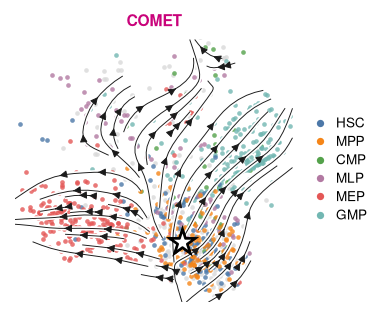

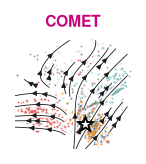

In [5]:
def plot_arrows(ds, method, style="big", panel_in=None, ax=None, title=True, legend=True):
    '''one method's arrows over the cell types on the Decipher 2D embedding (COMET also gets its origin star)'''
    panel_in = panel_in or {"big": 2.4, "small": 1.0}.get(style, 2.4)
    if ax is None: _, ax = plt.subplots(figsize=(panel_in, panel_in * 0.95))
    embedding_panel(ax, ds, method, panel_in, style)
    if title: ax.set_title(method, color=COLORS.get(method, "k"), fontweight="bold")
    if legend:
        lab = R[ds]["lab"].astype(str)
        ax.legend(handles=celltype_handles(ds, lab, celltype_palette(ds, lab)), loc="center left",
                  bbox_to_anchor=(1.0, 0.5), handletextpad=0.2, labelspacing=0.35)
    return ax

plot_arrows("hema", "COMET", style="big");
plot_arrows("hema", "COMET", style="small", legend=False);

## Figure 1: benchmark overview
* **Rows:** datasets. **Columns:** Ground Truth (Decipher embedding coloured by known cell type), COMET pseudotime, then each method's arrows. The star marks COMET's inferred origin.
* **Right block:** the three metrics, with one row per method in the same order as the arrow columns.
* **Cell colour:** difference from chance, with blue better and red worse. Each metric uses one colour scale shared across datasets.
* **Bold** is the best in the dataset. *Grey italic* means the 95% CI overlaps chance.
* Grey cells lie outside the scored cell-type tree.
* **Panel letters:** one per dataset row (a, b, …), in the order Paul et al. 2015, Velten et al. 2017, Nestorowa et al. 2016, Ma et al. 2020, Nazaret et al. 2025.

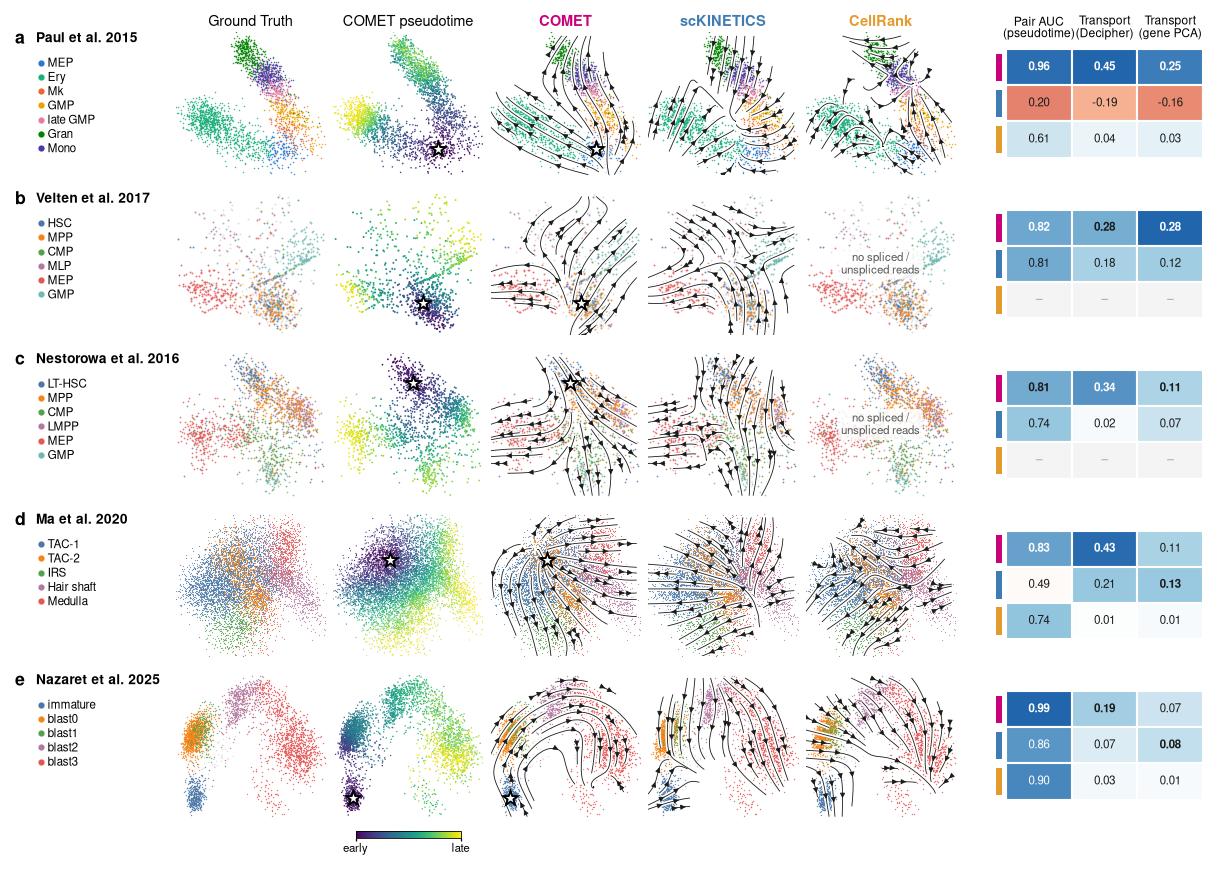

In [6]:
def metric_block(ax, ds, spans, header=False, fontsize=5.6):
    '''methods × metrics heatmap for one dataset (rows in METHODS order); spans: per-metric colour half-range'''
    for j, (me, sp, lab) in enumerate(METRICS):
        c0, clo, chi = chance(ds, me, sp)
        best = np.nanmax([get(ds, m, me, sp)[0] for m in METHODS])
        for i, m in enumerate(METHODS):
            v, lo, hi = get(ds, m, me, sp)
            if not np.isfinite(v):
                ax.add_patch(Rectangle((j, i), 1, 1, fc="#F4F4F4", ec="white", lw=1.0))
                ax.text(j + .5, i + .5, "–", ha="center", va="center", fontsize=fontsize, color="0.6"); continue
            dv = (v - c0) / spans[j]; ns = lo <= chi and hi >= clo
            ax.add_patch(Rectangle((j, i), 1, 1, fc=DIVERGING(0.5 + 0.5 * np.clip(dv, -1, 1)), ec="white", lw=1.0))
            ax.text(j + .5, i + .5, f"{v:.2f}", ha="center", va="center", fontsize=fontsize,
                    fontweight="bold" if (v >= best and not ns) else "normal", fontstyle="italic" if ns else "normal",
                    color="0.55" if ns else ("white" if abs(dv) > 0.65 else "0.1"))
    for i, m in enumerate(METHODS):                                                  # method colour key
        ax.add_patch(Rectangle((-0.16, i + 0.12), 0.09, 0.76, fc=COLORS[m], ec="none", clip_on=False))
    ax.set_xlim(-0.2, len(METRICS)); ax.set_ylim(len(METHODS), 0); ax.axis("off")
    if header:
        for j, lab in enumerate(["Pair AUC\n(pseudotime)", "Transport\n(Decipher)", "Transport\n(gene PCA)"]):
            ax.text(j + .5, -0.25, lab, ha="center", va="bottom", fontsize=5.8, linespacing=1.05)

def metric_spans():
    out = []
    for me, sp, _ in METRICS:
        out.append(np.nanmax([abs(get(ds, m, me, sp)[0] - chance(ds, me, sp)[0]) for ds in DATASETS for m in METHODS]))
    return out

OVERVIEW_NAMES = {"paul15": "Paul et al. 2015", "hema": "Velten et al. 2017", "nestorowa": "Nestorowa et al. 2016",
                  "ma2020": "Ma et al. 2020", "aml89": "Nazaret et al. 2025"}   # row order and row names of the overview figures
OVERVIEW_ORDER = list(OVERVIEW_NAMES)

def overview_figure(dss=None, P=1.0, save_as="fig0_overview", truth_arrows=False, letters=True):
    dss = [d for d in OVERVIEW_ORDER if d in (dss or DATASETS)]; kinds = ["truth" if truth_arrows else "celltypes", "pseudotime"] + METHODS
    LEG, GAP, HGAP, HM, HEAD, RG, FOOT = 1.07, 0.05, 0.25, 1.4, 0.42, 0.12, 0.28
    PH = P * 0.95; W = LEG + len(kinds) * P + (len(kinds) - 1) * GAP + HGAP + HM + 0.05
    H = HEAD + len(dss) * PH + (len(dss) - 1) * RG + FOOT
    fig = plt.figure(figsize=(W, H)); spans = metric_spans()
    for i, ds in enumerate(dss):
        y = H - HEAD - (i + 1) * PH - i * RG
        lab = R[ds]["lab"].astype(str); pal = celltype_palette(ds, lab)
        for k, kind in enumerate(kinds):
            x = LEG + k * (P + GAP); ax = fig.add_axes([x / W, y / H, P / W, PH / H])
            sc = embedding_panel(ax, ds, kind, P, "small")
            if i == 0:
                t = {"celltypes": "Ground Truth", "truth": "Ground Truth", "pseudotime": "COMET pseudotime"}.get(kind, kind)
                ax.set_title(t, fontsize=7, pad=3, fontweight="regular" if kind in ("celltypes", "truth", "pseudotime") else "bold",
                             color=COLORS.get(kind, "k"))
            if kind == "pseudotime" and i == len(dss) - 1:                          # one colour bar, under its column
                cax = fig.add_axes([(x + 0.15 * P) / W, (y - 0.14) / H, 0.7 * P / W, 0.045 / H])
                cb = fig.colorbar(sc, cax=cax, orientation="horizontal", ticks=[0, 1])
                cb.ax.set_xticklabels(["early", "late"]); cb.ax.tick_params(labelsize=5.5, length=1.5, pad=1)
                cb.outline.set_linewidth(0.4)
        # row letter + dataset name + cell-type key on the left
        if letters: fig.text(0.0, (y + PH + 0.01) / H, "abcdefgh"[i], fontsize=8.5, fontweight="bold", va="top", ha="left")
        fig.text((0.14 if letters else 0.0) / W, (y + PH) / H, OVERVIEW_NAMES[ds], fontsize=6.6, fontweight="bold",
                 va="top", ha="left")
        hs = celltype_handles(ds, lab, pal, ms=3.0)
        lax = fig.add_axes([(0.14 if letters else 0.0) / W, y / H, (LEG - 0.16) / W, (PH - 0.17) / H]); lax.axis("off")
        lax.legend(handles=hs, loc="upper left", borderaxespad=0, handletextpad=0.1, labelspacing=0.18,
                   fontsize=5.6, handlelength=0.9, borderpad=0)
        # metrics block
        hx = LEG + len(kinds) * P + (len(kinds) - 1) * GAP + HGAP
        hax = fig.add_axes([hx / W, (y + 0.12 * PH) / H, HM / W, 0.76 * PH / H])
        metric_block(hax, ds, spans, header=(i == 0))
    save(fig, save_as); return fig

overview_figure();   # rows: paul15 first, AML last (OVERVIEW_ORDER)

## Figure 1b: datasets with CellRank results
The same layout as Figure 1, restricted to the three datasets with spliced/unspliced reads, so all three methods are compared on each.

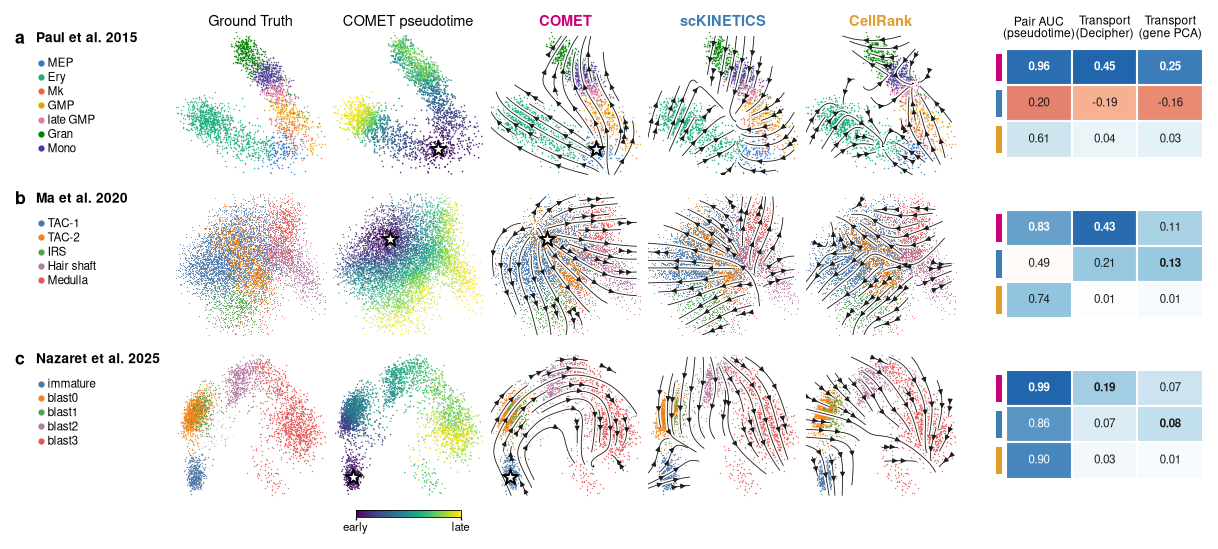

In [7]:
overview_figure(["paul15", "aml89", "ma2020"], save_as="fig0b_overview_cellrank");

## Figures 1c and 1d: with the expected trajectory
The same as Figures 1 and 1b. In the Ground Truth column, big arrows mark the expected direction of movement: one arrow per parent → child edge of the cell-type tree that every metric scores against (`nm.TREES`). Each arrow runs from the parent cluster's centre to the child's, routed along the cells.

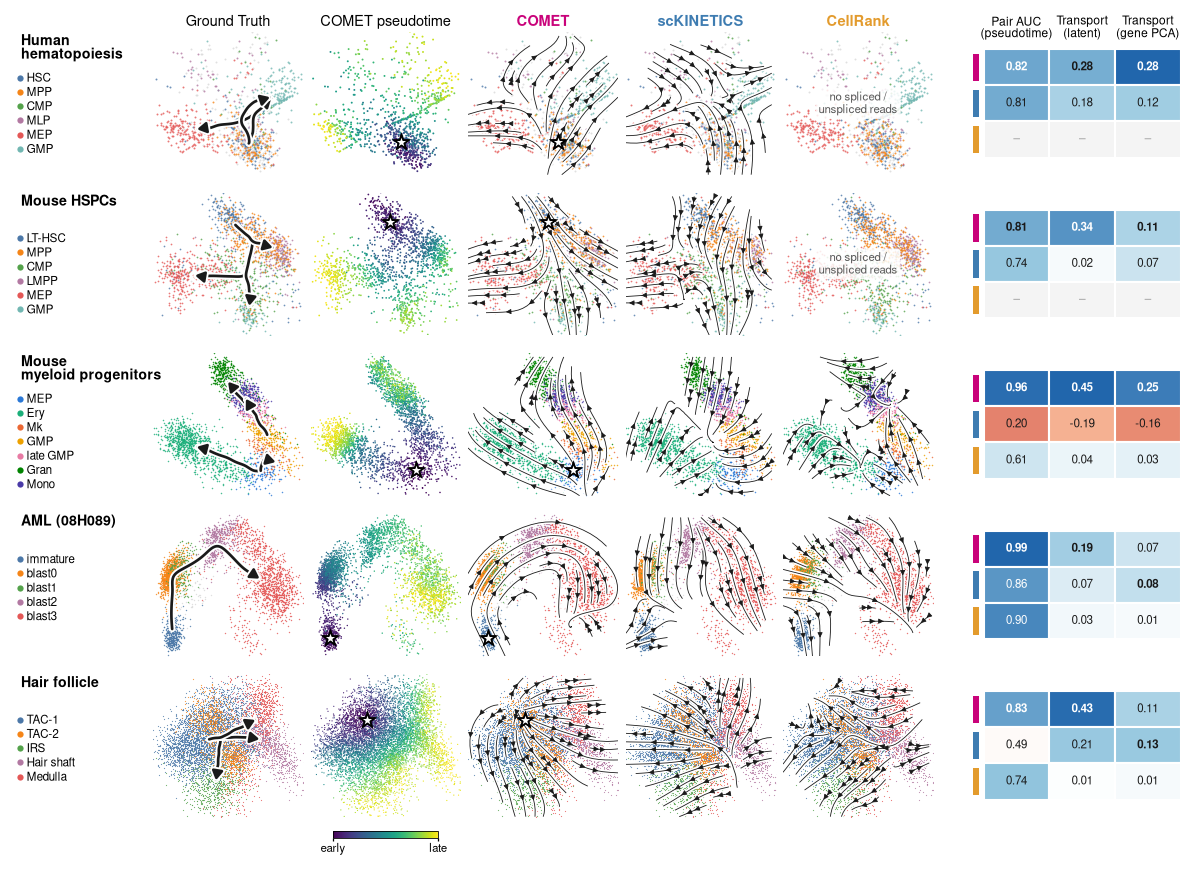

In [8]:
overview_figure(save_as="fig0c_overview_truth", truth_arrows=True);

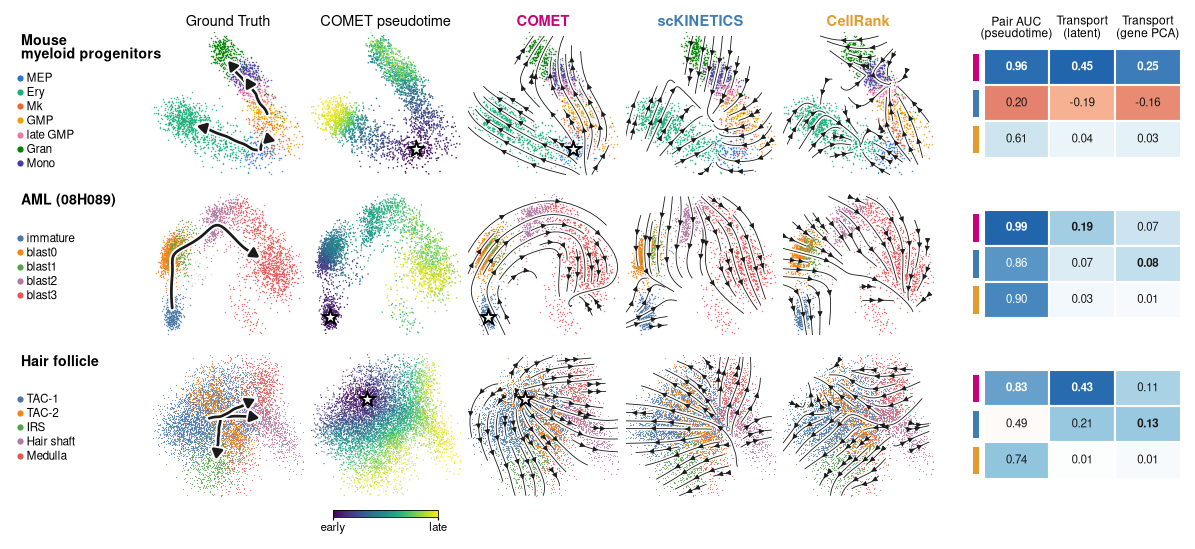

In [9]:
overview_figure(["paul15", "aml89", "ma2020"], save_as="fig0d_overview_cellrank_truth", truth_arrows=True);

## Figure 2: arrows on the Decipher embedding
Arrows for every method and dataset, in the same layout as the overview but larger.

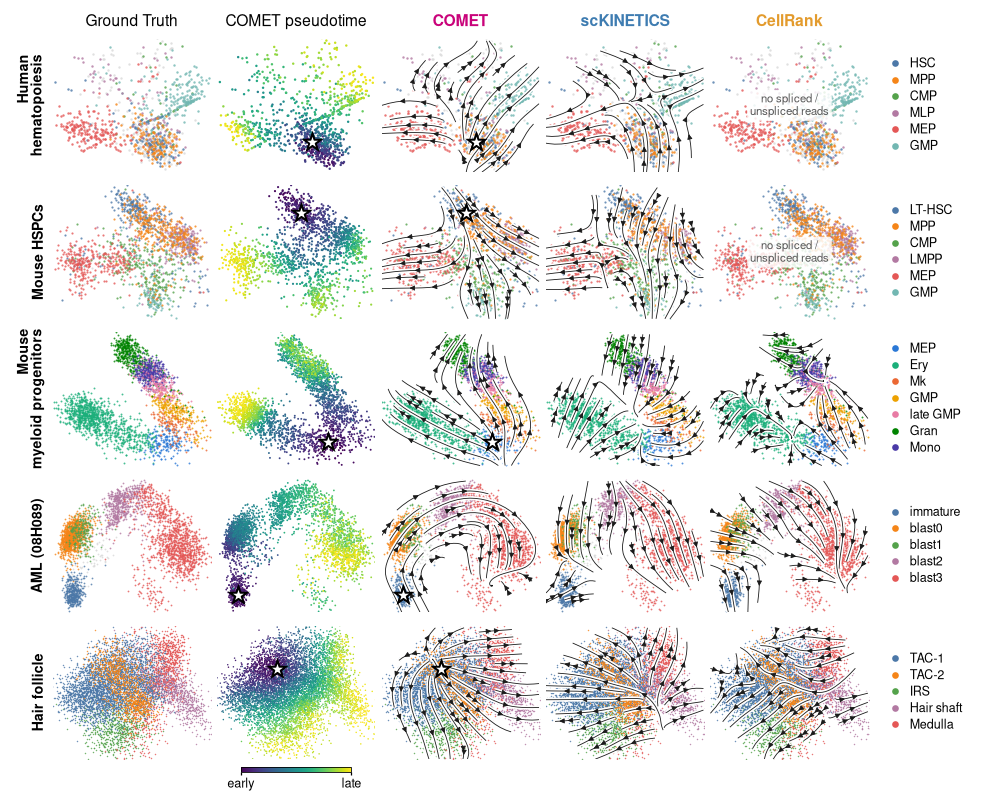

In [10]:
def arrows_grid(dss=None, P=1.25, style="small", save_as="fig1_arrows_decipher2d"):
    dss = list(dss or DATASETS); kinds = ["celltypes", "pseudotime"] + METHODS
    fig, axes = plt.subplots(len(dss), len(kinds), figsize=(P * len(kinds) + 1.1, P * 0.95 * len(dss) + 0.3),
                             squeeze=False, gridspec_kw=dict(wspace=0.04, hspace=0.1, left=0.12, right=0.86))
    fig.canvas.draw()                                                               # fix axes positions first
    for i, ds in enumerate(dss):
        lab = R[ds]["lab"].astype(str); pal = celltype_palette(ds, lab)
        for k, kind in enumerate(kinds):
            sc = embedding_panel(axes[i, k], ds, kind, P, style)
            if kind == "pseudotime" and i == len(dss) - 1:
                cax = axes[i, k].inset_axes([0.15, -0.1, 0.7, 0.04])
                cb = fig.colorbar(sc, cax=cax, orientation="horizontal", ticks=[0, 1])
                cb.ax.set_xticklabels(["early", "late"]); cb.ax.tick_params(labelsize=6, length=1.5, pad=1)
                cb.outline.set_linewidth(0.4)
            if i == 0:
                axes[i, k].set_title({"celltypes": "Ground Truth", "pseudotime": "COMET pseudotime"}.get(kind, kind),
                                     color=COLORS.get(kind, "k"),
                                     fontweight="regular" if kind in ("celltypes", "pseudotime") else "bold")
        name = DATASETS[ds].replace(" ", "\n", 1) if len(DATASETS[ds]) > 14 else DATASETS[ds]
        axes[i, 0].text(-0.05, 0.5, name, transform=axes[i, 0].transAxes, rotation=90, ha="right",
                        va="center", fontsize=6.8, fontweight="bold", linespacing=1.05)
        axes[i, -1].legend(handles=celltype_handles(ds, lab, pal, ms=3.2), loc="center left", bbox_to_anchor=(1.02, 0.5),
                           handletextpad=0.15, labelspacing=0.25, fontsize=6)
    save(fig, save_as); return fig

arrows_grid();

## Figure 3: metric heatmap
* **Colour:** difference from chance (0.5 for pair AUC, the random-field median for transport). Blue is better and red is worse; scaled per column.
* **Bold** is the best in the dataset. *Grey italic* means the 95% CI overlaps chance.

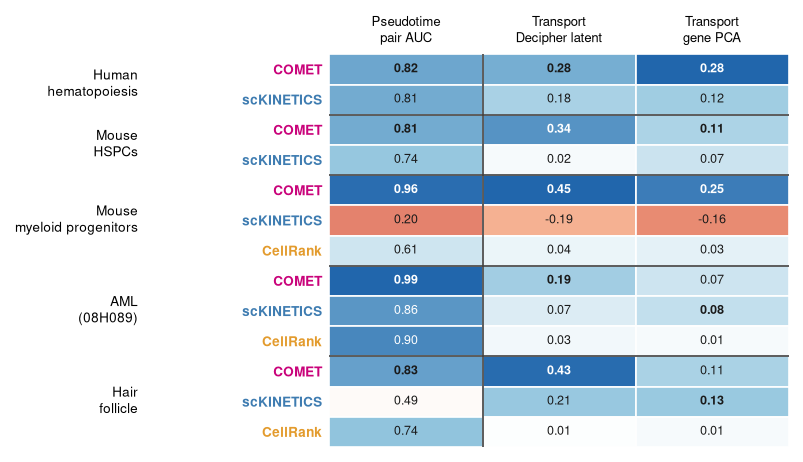

In [11]:
def heatmap(save_as="fig2_metric_heatmap"):
    rows = [(ds, m) for ds in DATASETS for m in METHODS if np.isfinite(get(ds, m, "pair AUC", "pseudotime")[0])]
    M = np.array([[get(ds, m, me, sp)[0] for me, sp, _ in METRICS] for ds, m in rows])
    D0 = M - np.array([[chance(ds, me, sp)[0] for me, sp, _ in METRICS] for ds, m in rows])
    fig, ax = plt.subplots(figsize=(0.75 * len(METRICS) + 1.7, 0.2 * len(rows) + 0.8))
    for j, (me, sp, _) in enumerate(METRICS):
        span = np.nanmax(np.abs(D0[:, j])) or 1
        for i, (ds, m) in enumerate(rows):
            v = D0[i, j]
            ax.add_patch(Rectangle((j, i), 1, 1, fc="#F4F4F4" if not np.isfinite(v) else DIVERGING(0.5 + 0.5 * v / span),
                                   ec="white", lw=0.8))
            if not np.isfinite(M[i, j]):
                ax.text(j + .5, i + .5, "–", ha="center", va="center", color="0.65", fontsize=6); continue
            val, lo, hi = get(ds, m, me, sp); c0, clo, chi = chance(ds, me, sp); ns = lo <= chi and hi >= clo
            best = val >= np.nanmax([get(ds, mm, me, sp)[0] for mm in METHODS])
            ax.text(j + .5, i + .5, f"{val:.2f}", ha="center", va="center", fontsize=6,
                    fontweight="bold" if best and not ns else "normal", fontstyle="italic" if ns else "normal",
                    color="0.55" if ns else ("white" if abs(v) > 0.7 * span else "0.1"))
    ax.set_xlim(0, len(METRICS)); ax.set_ylim(len(rows), 0)
    ax.set_xticks(np.arange(len(METRICS)) + .5, [l for *_, l in METRICS], fontsize=6.3)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    ax.set_yticks(np.arange(len(rows)) + .5, [m for _, m in rows])
    for t, (_, m) in zip(ax.get_yticklabels(), rows): t.set_color(COLORS[m]); t.set_fontweight("bold")
    for s_ in ax.spines.values(): s_.set_visible(False)
    start = 0
    for ds in DATASETS:
        n = sum(1 for d, _ in rows if d == ds)
        ax.text(-1.25, start + n / 2, DATASETS[ds].replace(" ", "\n", 1), ha="right", va="center", fontsize=6.5)
        if start: ax.axhline(start, color="0.25", lw=0.8)
        start += n
    ax.axvline(1, color="0.25", lw=0.8)
    save(fig, save_as); return fig

heatmap();

## Figure 4: metrics with 95% CIs
The grey band is chance: 95% of random fields for transport, 0.5 for pair AUC.

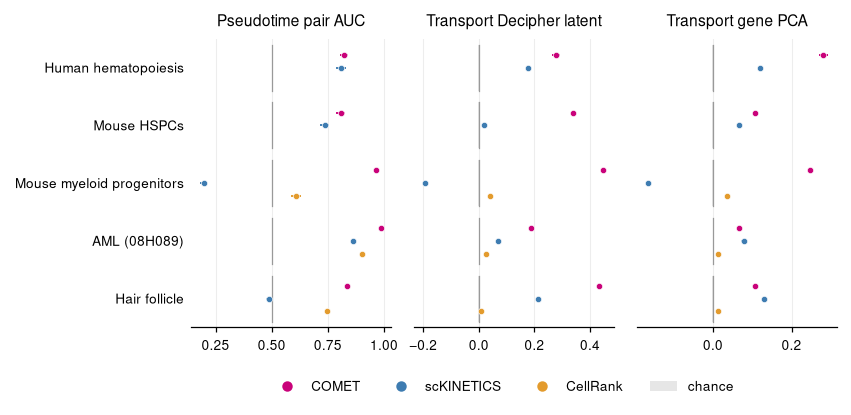

In [12]:
def forest(save_as="fig3_metric_forest"):
    dss = list(DATASETS); off = dict(zip(METHODS, [-0.22, 0.0, 0.22]))
    fig, axes = plt.subplots(1, len(METRICS), figsize=(1.85 * len(METRICS), 2.5), sharey=True, gridspec_kw=dict(wspace=0.12))
    for ax, (me, sp, lab) in zip(axes, METRICS):
        for y, ds in enumerate(dss):
            c0, clo, chi = chance(ds, me, sp)
            ax.add_patch(Rectangle((clo, y - 0.4), max(chi - clo, 1e-3), 0.8, fc=COLORS["null"], ec="none", zorder=0))
            ax.plot([c0, c0], [y - 0.4, y + 0.4], color="0.6", lw=0.6, zorder=1)
            for m in METHODS:
                v, lo, hi = get(ds, m, me, sp)
                if not np.isfinite(v): continue
                ax.errorbar(v, y + off[m], xerr=[[v - lo], [hi - v]], fmt="o", ms=3.0, color=COLORS[m], mec="white",
                            mew=0.3, elinewidth=0.9, capsize=0, zorder=3)
        ax.set_title(lab.replace("\n", " ")); ax.set_ylim(len(dss) - 0.5, -0.5)
        ax.grid(axis="x", color="0.93", lw=0.5); ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    axes[0].set_yticks(range(len(dss)), [DATASETS[d] for d in dss])
    h = [Line2D([], [], ls="", marker="o", ms=4, color=COLORS[m], label=m) for m in METHODS] + \
        [Patch(fc=COLORS["null"], ec="none", label="chance")]
    fig.legend(handles=h, loc="upper center", ncol=len(h), bbox_to_anchor=(0.5, 0.0))
    save(fig, save_as); return fig

forest();

## Figure 5: distributions
* **Top two rows:** per-cell forward transport. The white dot is the dataset value (cluster-balanced) with its 95% CI, so it need not equal the violin's mean. The grey band is chance.
* **Bottom row:** pair AUC of every ancestor → descendant pair (dots), with the mean and its 95% CI.

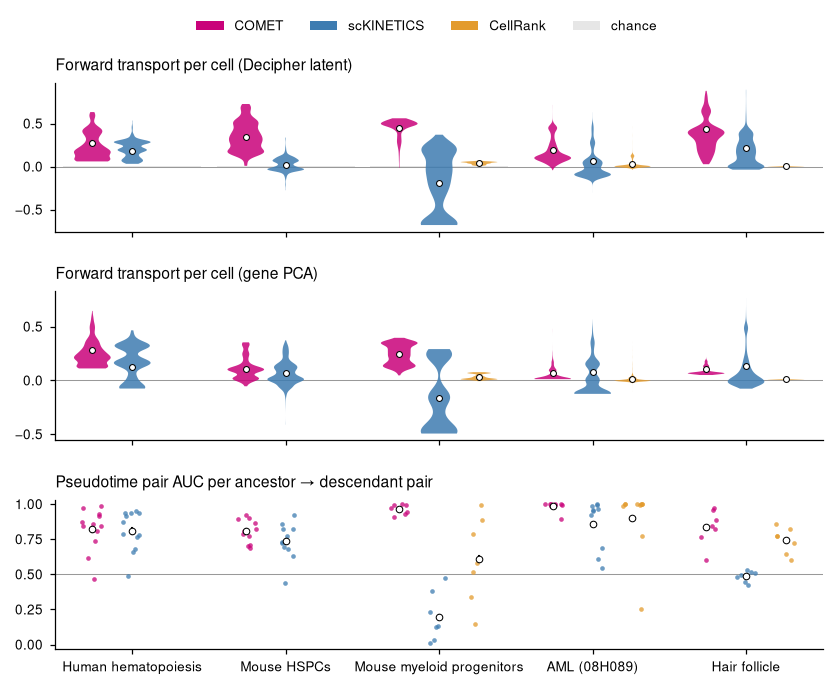

In [13]:
def violins(save_as="fig4_distributions"):
    dss = list(DATASETS); w = 0.26; rng = np.random.default_rng(0)
    fig, axes = plt.subplots(3, 1, figsize=(6.6, 4.9), sharex=True, gridspec_kw=dict(hspace=0.4))
    for ax, sp in zip(axes[:2], SPACES):
        for x, ds in enumerate(dss):
            c0, clo, chi = chance(ds, "transport", sp)
            ax.add_patch(Rectangle((x - 0.45, clo), 0.9, max(chi - clo, 1e-3), fc=COLORS["null"], ec="none", zorder=0))
            for k, m in enumerate(METHODS):
                if (sp, m) not in R[ds]["tr"]: continue
                v = R[ds]["tr"][sp, m]; v = v[np.isfinite(v)]; pos = x + (k - 1) * w
                vp = ax.violinplot([v], positions=[pos], widths=w * 0.92, showextrema=False, bw_method=0.25)
                for b in vp["bodies"]: b.set_facecolor(COLORS[m]); b.set_edgecolor("none"); b.set_alpha(0.85)
                val, lo, hi = get(ds, m, "transport", sp)
                ax.plot([pos, pos], [lo, hi], color="k", lw=1.0, zorder=3)
                ax.scatter([pos], [val], s=8, c="white", edgecolors="k", linewidths=0.5, zorder=4)
        ax.axhline(0, color="0.6", lw=0.5, zorder=0); ax.set_title(f"Forward transport per cell ({sp})", loc="left")
    ax = axes[2]
    for x, ds in enumerate(dss):
        for k, m in enumerate(METHODS):
            q = PAIRS.query("dataset==@ds and method==@m")
            if not len(q): continue
            pos = x + (k - 1) * w
            ax.scatter(pos + rng.uniform(-w * 0.25, w * 0.25, len(q)), q.value, s=5, color=COLORS[m], alpha=0.75, lw=0, zorder=2)
            val, lo, hi = get(ds, m, "pair AUC", "pseudotime")
            ax.plot([pos, pos], [lo, hi], color="k", lw=1.0, zorder=3)
            ax.scatter([pos], [val], s=10, c="white", edgecolors="k", linewidths=0.5, zorder=4)
    ax.axhline(0.5, color="0.6", lw=0.5, zorder=0); ax.set_ylim(-0.03, 1.03)
    ax.set_title("Pseudotime pair AUC per ancestor → descendant pair", loc="left")
    axes[-1].set_xticks(range(len(dss)), [DATASETS[d] for d in dss]); axes[-1].set_xlim(-0.5, len(dss) - 0.5)
    h = [Patch(fc=COLORS[m], label=m) for m in METHODS] + [Patch(fc=COLORS["null"], label="chance")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.93), ncol=len(h))
    save(fig, save_as); return fig

violins();

## Figure 6: stability of forward transport over the number of steps
The grey band covers 95% of random fields at each step. $k = 30$ is the value reported above.

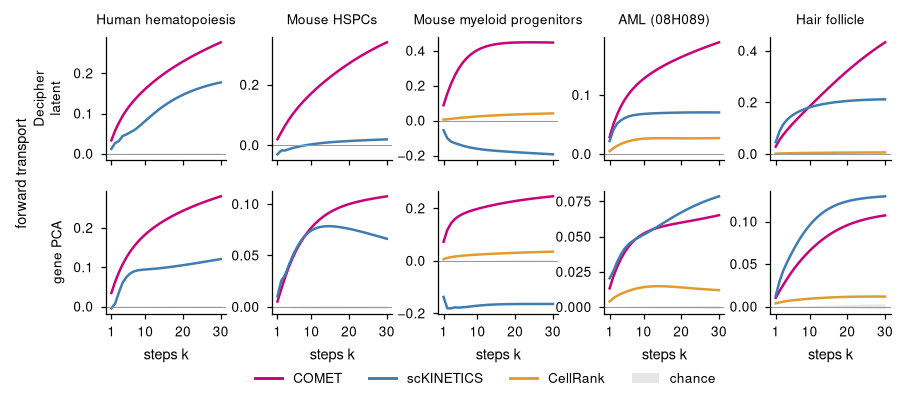

In [14]:
def stability(save_as="fig5_transport_vs_steps"):
    dss = list(DATASETS)
    fig, axes = plt.subplots(len(SPACES), len(dss), figsize=(1.35 * len(dss), 1.2 * len(SPACES)), sharex=True,
                             squeeze=False, gridspec_kw=dict(wspace=0.38, hspace=0.25))
    for r, sp in enumerate(SPACES):
        for c, ds in enumerate(dss):
            ax = axes[r, c]; k = np.arange(1, K_STEPS + 1); nc = R[ds]["null_curve"][sp]
            ax.fill_between(k, np.percentile(nc, 2.5, 0), np.percentile(nc, 97.5, 0), color=COLORS["null"], lw=0)
            for m in METHODS:
                if (sp, m) in R[ds]["curve"]: ax.plot(k, R[ds]["curve"][sp, m], color=COLORS[m], lw=1.2)
            ax.axhline(0, color="0.6", lw=0.5); ax.set_xticks([1, 10, 20, 30])
            if r == 0: ax.set_title(DATASETS[ds], fontsize=6.5)
            if c == 0: ax.set_ylabel(sp.replace("Decipher ", "Decipher\n"), fontsize=6.5)
    for ax in axes[-1]: ax.set_xlabel("steps k")
    h = [Line2D([], [], color=COLORS[m], lw=1.4, label=m) for m in METHODS] + [Patch(fc=COLORS["null"], label="chance")]
    fig.legend(handles=h, loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.text(0.05, 0.5, "forward transport", rotation=90, va="center", ha="right", fontsize=7)
    save(fig, save_as); return fig

stability();

## Figure 7: pseudotime by known cluster
Pseudotime is rank-normalised per method. Cells are grouped by cluster in tree order, and black bars mark medians.

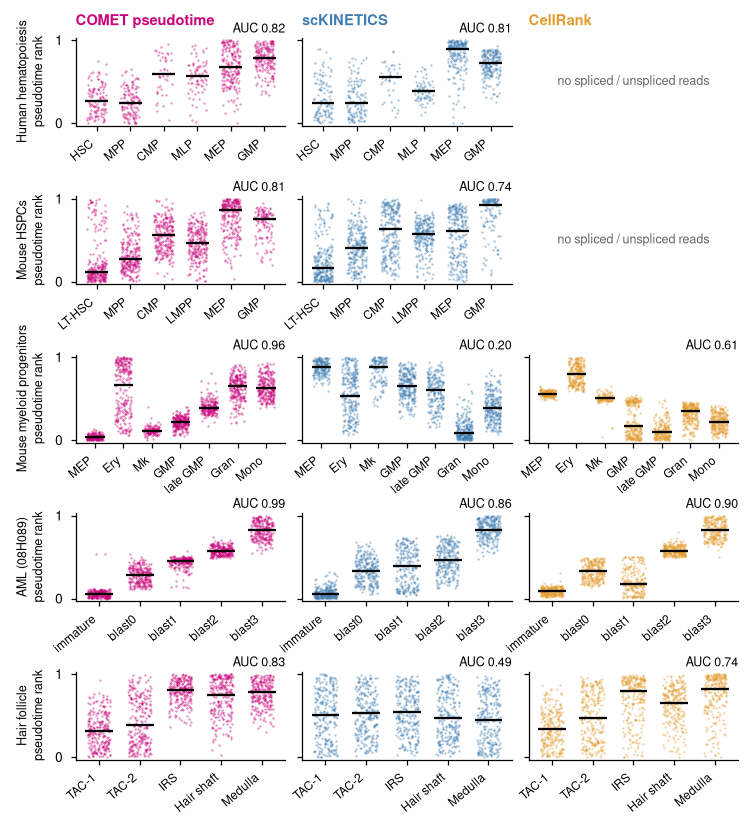

In [15]:
def pseudotime_strips(max_per=250, save_as="fig6_pseudotime_strips"):
    dss = list(DATASETS); rng = np.random.default_rng(0)
    label = {"COMET": "COMET pseudotime"}
    fig, axes = plt.subplots(len(dss), len(METHODS), figsize=(1.9 * len(METHODS), 1.25 * len(dss)), squeeze=False,
                             gridspec_kw=dict(wspace=0.08, hspace=0.8), sharey=True)
    for r, ds in enumerate(dss):
        lab = R[ds]["lab"].astype(str); order = [t for t in TREE_ORDER[ds] if (lab == t).any()]
        for k, m in enumerate(METHODS):
            ax = axes[r, k]
            if r == 0: ax.set_title(label.get(m, m), fontsize=7, fontweight="bold", color=COLORS[m], loc="left")
            if m not in R[ds]["pt"]:
                ax.axis("off"); ax.text(0.5, 0.5, "no spliced / unspliced reads", ha="center", va="center",
                                        transform=ax.transAxes, fontsize=6, color="0.4"); continue
            pt = R[ds]["pt"][m]; rk = (rankdata(pt) - 1) / (len(pt) - 1)
            for x, t in enumerate(order):
                idx = np.where(lab == t)[0]; sh = rng.choice(idx, min(len(idx), max_per), replace=False)
                ax.scatter(x + rng.uniform(-0.28, 0.28, len(sh)), rk[sh], s=1.2, lw=0, color=COLORS[m], alpha=0.45, rasterized=True)
                ax.hlines(np.median(rk[idx]), x - 0.34, x + 0.34, color="k", lw=1.1, zorder=3)
            ax.text(1.0, 1.02, f"AUC {get(ds, m, 'pair AUC', 'pseudotime')[0]:.2f}", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=6)
            ax.set_xticks(range(len(order)), [SHORT.get(t, t) for t in order], rotation=40, ha="right", fontsize=5.8)
            ax.set_ylim(-0.03, 1.03); ax.set_yticks([0, 1])
            if k == 0: ax.set_ylabel(f"{DATASETS[ds]}\npseudotime rank", fontsize=6)
    save(fig, save_as); return fig

pseudotime_strips();

## Table: value [95% CI]

In [16]:
def table():
    rows = []
    for ds in DATASETS:
        for m in METHODS + ["random field (null)"]:
            r = {"dataset": DATASETS[ds], "method": m}
            for me, sp, lab in METRICS:
                v, lo, hi = get(ds, m, me, sp)
                r[lab.replace("\n", " ")] = "—" if not np.isfinite(v) else f"{v:.3f} [{lo:.3f}, {hi:.3f}]"
            if any(x != "—" for k, x in r.items() if k not in ("dataset", "method")): rows.append(r)
    return pd.DataFrame(rows).set_index(["dataset", "method"])

T = table(); T.to_csv(f"{FIGS}/table.csv"); T

Pseudotime pair AUC  \
dataset                   method                                      
Human hematopoiesis       COMET                0.821 [0.804, 0.839]   
                          scKINETICS           0.809 [0.787, 0.831]   
                          random field (null)                     —   
Mouse HSPCs               COMET                0.808 [0.786, 0.826]   
                          scKINETICS           0.735 [0.717, 0.755]   
                          random field (null)                     —   
Mouse myeloid progenitors COMET                0.964 [0.956, 0.972]   
                          scKINETICS           0.199 [0.183, 0.212]   
                          CellRank             0.608 [0.586, 0.630]   
                          random field (null)                     —   
AML (08H089)              COMET                0.986 [0.983, 0.989]   
                          scKINETICS           0.862 [0.856, 0.867]   
                          CellRank             0.901 [0.893, 0.908]   
                          random field (null)                     —   
Hair follicle             COMET                0.834 [0.828, 0.842]   
                          scKINETICS           0.487 [0.475, 0.496]   
                          CellRank             0.744 [0.735, 0.753]   
                          random field (null)                     —   

                                              Transport Decipher latent  \
dataset                   method                                          
Human hematopoiesis       COMET                    0.277 [0.263, 0.291]   
                          scKINETICS               0.177 [0.171, 0.185]   
                          random field (null)    -0.000 [-0.001, 0.002]   
Mouse HSPCs               COMET                    0.340 [0.333, 0.348]   
                          scKINETICS               0.019 [0.015, 0.024]   
                          random field (null)     0.001 [-0.001, 0.002]   
Mouse myeloid progenitors COMET                    0.447 [0.441, 0.452]   
                          scKINETICS            -0.193 [-0.199, -0.187]   
                          CellRank                 0.041 [0.040, 0.042]   
                          random field (null)    -0.000 [-0.002, 0.002]   
AML (08H089)              COMET                    0.189 [0.185, 0.193]   
                          scKINETICS               0.070 [0.064, 0.076]   
                          CellRank                 0.027 [0.025, 0.030]   
                          random field (null)    -0.000 [-0.001, 0.000]   
Hair follicle             COMET                    0.433 [0.427, 0.438]   
                          scKINETICS               0.212 [0.207, 0.216]   
                          CellRank                 0.006 [0.006, 0.006]   
                          random field (null)    -0.000 [-0.001, 0.001]   

                                                    Transport gene PCA  
dataset                   method                                        
Human hematopoiesis       COMET                   0.280 [0.270, 0.291]  
                          scKINETICS              0.121 [0.115, 0.127]  
                          random field (null)    0.000 [-0.001, 0.002]  
Mouse HSPCs               COMET                   0.108 [0.103, 0.112]  
                          scKINETICS              0.066 [0.061, 0.072]  
                          random field (null)    0.000 [-0.001, 0.001]  
Mouse myeloid progenitors COMET                   0.246 [0.242, 0.250]  
                          scKINETICS           -0.164 [-0.169, -0.159]  
                          CellRank                0.035 [0.034, 0.036]  
                          random field (null)    0.000 [-0.002, 0.004]  
AML (08H089)              COMET                   0.065 [0.063, 0.068]  
                          scKINETICS              0.079 [0.072, 0.085]  
                          CellRank                0.012 [0.010, 0.014]  
                          rando

## Supplement
### Pair AUC for every ancestor → descendant pair

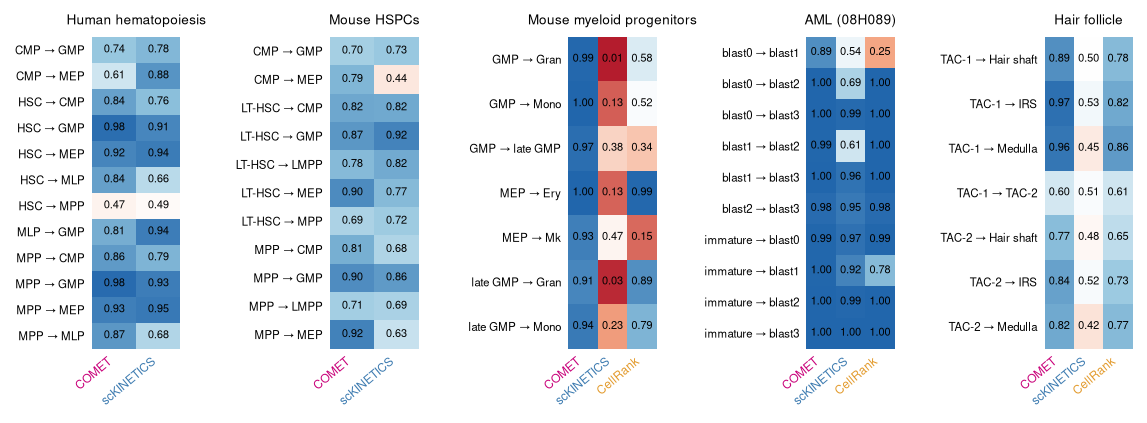

In [17]:
def pair_auc_heatmap(save_as="figS1_pair_auc"):
    dss = list(DATASETS)
    fig, axes = plt.subplots(1, len(dss), figsize=(1.55 * len(dss) + 1.2, 2.7), gridspec_kw=dict(wspace=1.7))
    for ax, ds in zip(axes, dss):
        P_ = PAIRS.query("dataset==@ds").pivot(index="pair", columns="method", values="value")
        P_ = P_[[m for m in METHODS if m in P_]]
        P_.index = [" → ".join(SHORT.get(t, t) for t in s.split(" → ")) for s in P_.index]
        ax.imshow(P_.values, cmap=DIVERGING, vmin=0, vmax=1, aspect="auto")
        for i in range(P_.shape[0]):
            for j in range(P_.shape[1]):
                ax.text(j, i, f"{P_.values[i, j]:.2f}", ha="center", va="center", fontsize=5.3)
        ax.set_xticks(range(P_.shape[1]), P_.columns, rotation=40, ha="right", fontsize=5.8)
        for t, c in zip(ax.get_xticklabels(), P_.columns): t.set_color(COLORS[c])
        ax.set_yticks(range(P_.shape[0]), P_.index, fontsize=5.5); ax.set_title(DATASETS[ds], fontsize=6.5)
        ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
    save(fig, save_as); return fig

pair_auc_heatmap();

### Arrow fields per dataset (big style)

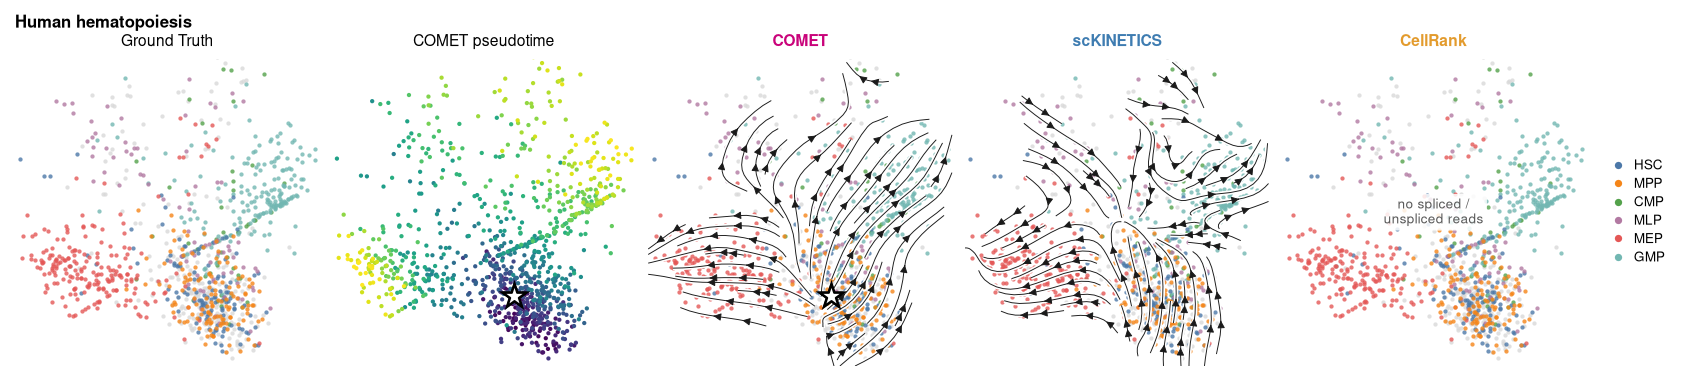

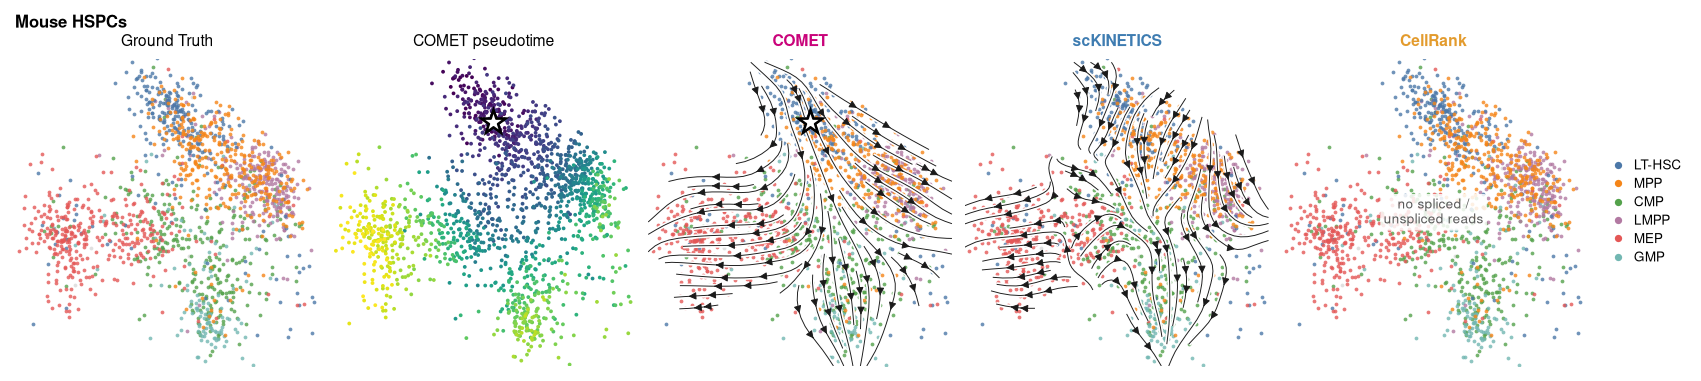

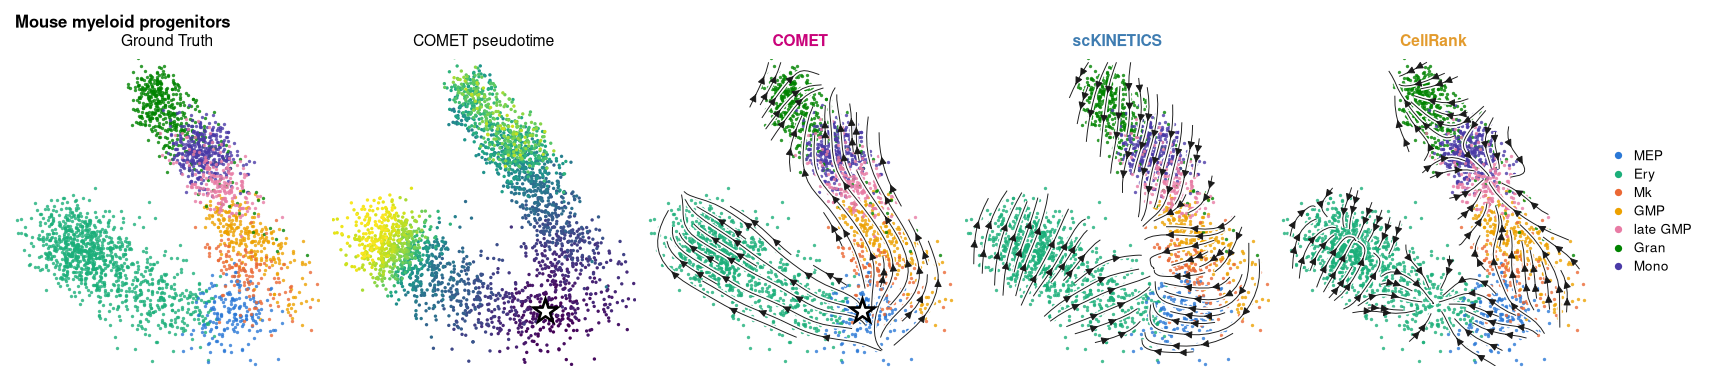

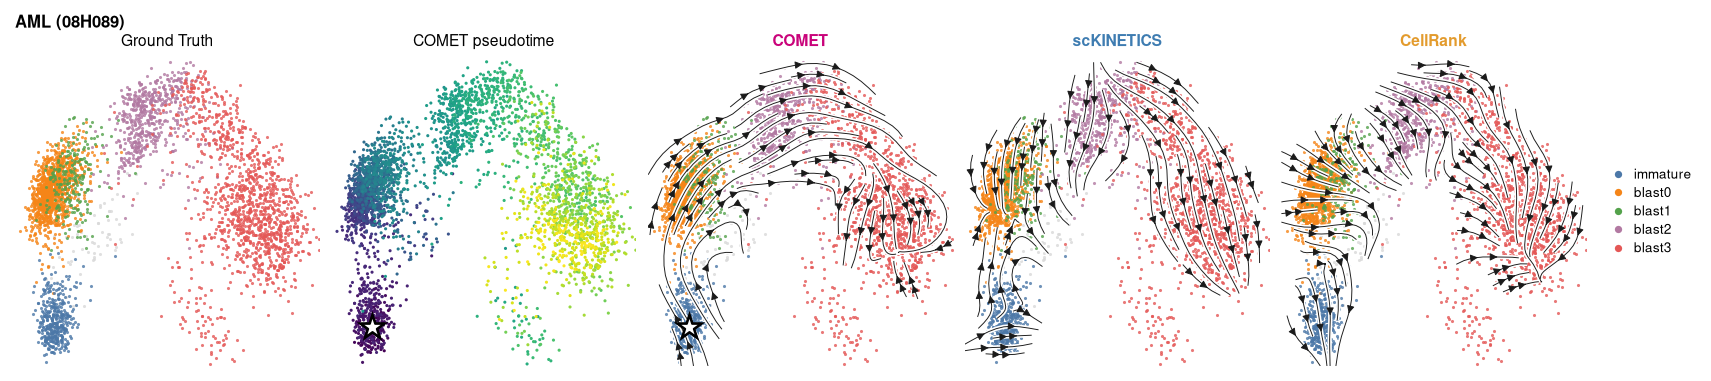

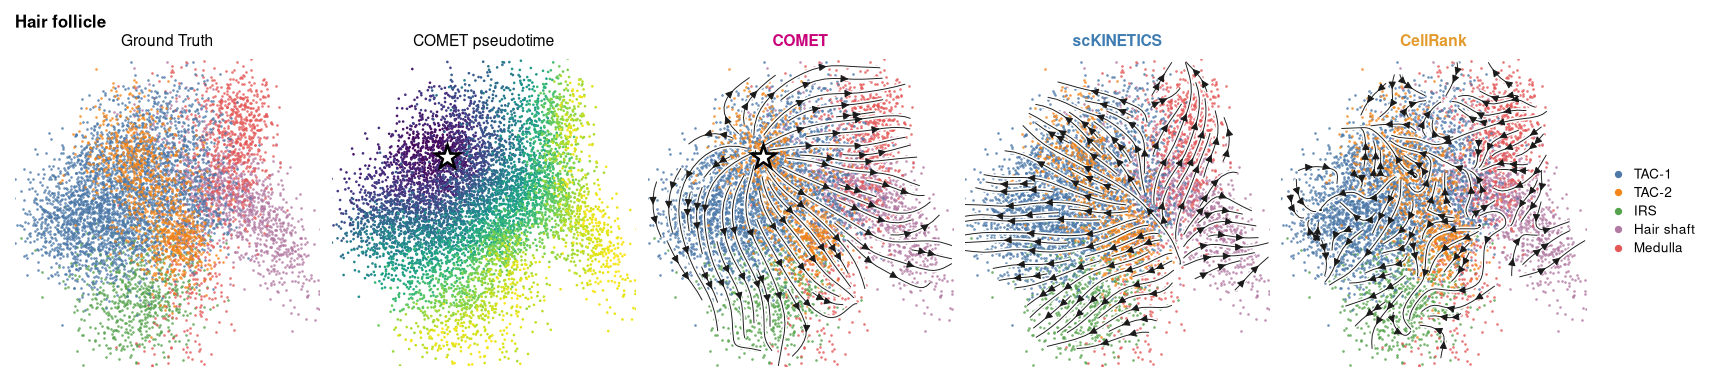

In [18]:
def arrows_dataset(ds, P=2.2, save_as=None):
    kinds = ["celltypes", "pseudotime"] + METHODS
    fig, axes = plt.subplots(1, len(kinds), figsize=(P * len(kinds) + 0.9, P * 0.95 + 0.35),
                             gridspec_kw=dict(wspace=0.04, left=0.01, right=0.89, top=0.86, bottom=0.02))
    lab = R[ds]["lab"].astype(str); pal = celltype_palette(ds, lab)
    for ax, kind in zip(axes, kinds):
        embedding_panel(ax, ds, kind, P, "big")
        ax.set_title({"celltypes": "Ground Truth", "pseudotime": "COMET pseudotime"}.get(kind, kind),
                     color=COLORS.get(kind, "k"), fontweight="regular" if kind in ("celltypes", "pseudotime") else "bold")
    axes[-1].legend(handles=celltype_handles(ds, lab, pal), loc="center left", bbox_to_anchor=(1.02, 0.5),
                    handletextpad=0.2, labelspacing=0.35)
    fig.suptitle(DATASETS[ds], fontsize=8, fontweight="bold", x=0.01, ha="left")
    save(fig, save_as or f"figS2_arrows_{ds}"); return fig

for ds in DATASETS:
    arrows_dataset(ds)

### The five Decipher embeddings (PNG only)

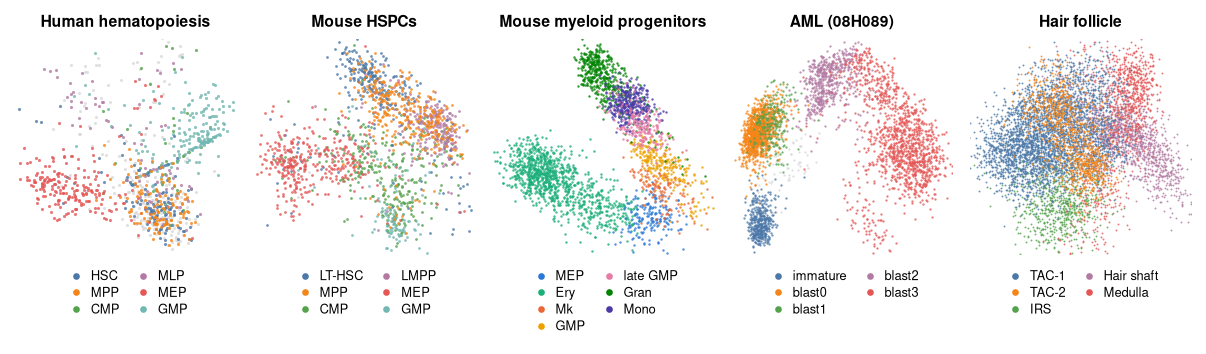

In [19]:
def decipher_spaces(P=1.6, save_as="decipher_spaces"):
    """the five Decipher 2D embeddings coloured by cell type, side by side (PNG only)"""
    dss = list(DATASETS)
    fig, axes = plt.subplots(1, len(dss), figsize=(P * len(dss), P * 0.95 + 0.95),
                             gridspec_kw=dict(wspace=0.08, left=0.01, right=0.99, top=0.88, bottom=0.3))
    for ax, ds in zip(axes, dss):
        lab = R[ds]["lab"].astype(str); pal = celltype_palette(ds, lab)
        embedding_panel(ax, ds, "celltypes", P, "big")
        ax.set_title(DATASETS[ds], fontsize=7.5, fontweight="bold")
        ax.legend(handles=celltype_handles(ds, lab, pal, ms=3.2), loc="upper center", bbox_to_anchor=(0.5, -0.02),
                  ncol=2, handletextpad=0.15, columnspacing=0.8, labelspacing=0.25, fontsize=6.2)
    save(fig, save_as, formats=("png",)); return fig

decipher_spaces();